# Orbis — Notebook inicial de planeación y verificación

**Proyecto:** Orbis — Sistema de visión para localización, estimación de pose y seguimiento de objetos planos.
**Fase actual:** Fase 1 (detección + pose + Kalman).
**Autor:** Sergio Abraham Ocampo Pérez.

Este notebook sirve como:
1. Checklist de tareas por fase.
2. Verificación del entorno.
3. Prueba de humo sobre tus 21 escenas para elegir la mejor pareja referencia–escena.
4. Experimentación mínima antes de pasar código a `src/`.

## 0. Checklist general del Proyecto 1

### Fase 1 — Pipeline clásico + pose + Kalman

- [x] Entorno instalado y verificado (`opencv-contrib-python`, `numpy`, `pyyaml`, `matplotlib`, `filterpy`).
- [x] Estructura de carpetas del repo creada.
- [ ] `configs/default.yaml` cargado correctamente.
- [ ] Imágenes organizadas: `data/reference/libro.jpg` y `data/scenes/esc_01.jpg` … `esc_21.jpg`.
- [ ] Detección de keypoints y descriptores con SIFT y ORB (interfaz común).
- [ ] Matching con ratio test de Lowe y cross-check.
- [ ] Homografía con RANSAC + filtrado de inliers.
- [ ] Proyección del contorno del objeto sobre la escena (imagen estática).
- [ ] Pose estimation con `solvePnP` + dibujo de ejes 3D.
- [ ] Filtro de Kalman sobre la pose (suavizado y predicción).
- [ ] Pipeline de video integrando detección + tracking.
- [ ] Comparativa SIFT vs ORB (tiempo vs robustez).
- [ ] Tests unitarios (`test_matcher.py`, `test_homography.py`, `test_kalman.py`).
- [ ] Figuras y resultados para el reporte.

### Fase 2 — Futuro

- [ ] Multi-objeto / multi-referencia.
- [ ] Robustez a oclusión, motion blur, iluminación.
- [ ] Tiempo real / GPU / métodos aprendidos.
- [ ] Métricas de tracking (jitter, drift, tasa de pérdida).
- [ ] Integración AR.

In [1]:
import sys
import cv2
import numpy as np
import yaml
import matplotlib
import filterpy

print("Python:", sys.version.split()[0])
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("PyYAML:", yaml.__version__)
print("Matplotlib:", matplotlib.__version__)
print("FilterPy:", filterpy.__version__)

Python: 3.12.3
OpenCV: 5.0.0
NumPy: 2.5.4
PyYAML: 6.0.3
Matplotlib: 3.11.2
FilterPy: 2.0.0


In [2]:
sift = cv2.SIFT_create()
orb = cv2.ORB_create(nfeatures=1000)
print("SIFT OK:", sift is not None)
print("ORB  OK:", orb is not None)
print("solvePnP disponible:", hasattr(cv2, "solvePnP"))
print("KalmanFilter disponible:", hasattr(cv2, "KalmanFilter"))

SIFT OK: True
ORB  OK: True
solvePnP disponible: True
KalmanFilter disponible: True


In [3]:
from pathlib import Path

cfg_path = Path("../configs/default.yaml")
if cfg_path.exists():
    with open(cfg_path, "r") as f:
        cfg = yaml.safe_load(f)
    print("Detector configurado:", cfg["features"]["detector"])
    print("Ratio test:", cfg["matching"]["ratio_test"])
    print("RANSAC threshold:", cfg["homography"]["ransac_threshold"])
    print("Kalman enable:", cfg["tracking"]["enable"])
else:
    print("No se encontró configs/default.yaml — revisa la ruta.")

Detector configurado: ORB
Ratio test: 0.75
RANSAC threshold: 3.0
Kalman enable: True


Referencia: (1300, 1300, 3)


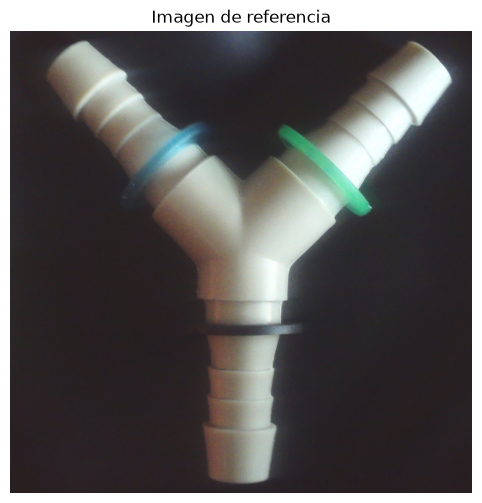

In [4]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

def show(img, title="", cmap=None):
    plt.figure(figsize=(10, 6))
    if img is None:
        print(f"[show] Imagen vacía: {title}")
        return
    if img.ndim == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap or "gray")
    plt.title(title)
    plt.axis("off")
    plt.show()

REF_PATH = Path("../data/reference/libro.jpg")
SCENES_DIR = Path("../data/scenes")

ref = cv2.imread(str(REF_PATH))
print("Referencia:", None if ref is None else ref.shape)
if ref is not None:
    show(ref, "Imagen de referencia")

Escenas encontradas: 21
  esc_01.jpg: (1140, 1140, 3)
  esc_02.jpg: (1440, 2560, 3)
  esc_03.jpg: (1440, 2560, 3)
  esc_04.jpg: (1440, 2560, 3)
  esc_05.jpg: (1440, 2560, 3)
  esc_06.jpg: (1440, 2560, 3)
  esc_07.jpg: (1440, 2560, 3)
  esc_08.jpg: (1440, 2560, 3)
  esc_09.jpg: (1440, 2560, 3)
  esc_10.jpg: (1440, 2560, 3)
  esc_11.jpg: (1440, 2560, 3)
  esc_12.jpg: (1440, 2560, 3)
  esc_13.jpg: (1440, 2560, 3)
  esc_14.jpg: (1440, 2560, 3)
  esc_15.jpg: (1440, 2560, 3)
  esc_16.jpg: (1440, 2560, 3)
  esc_17.jpg: (1440, 2560, 3)
  esc_18.jpg: (1440, 2560, 3)
  esc_19.jpg: (1440, 2560, 3)
  esc_20.jpg: (1440, 2560, 3)
  esc_21.jpg: (1440, 2560, 3)


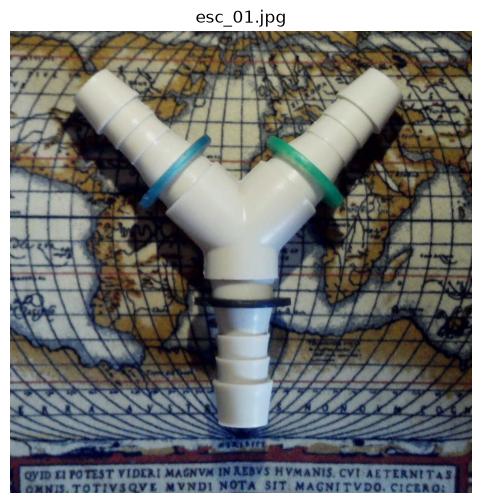

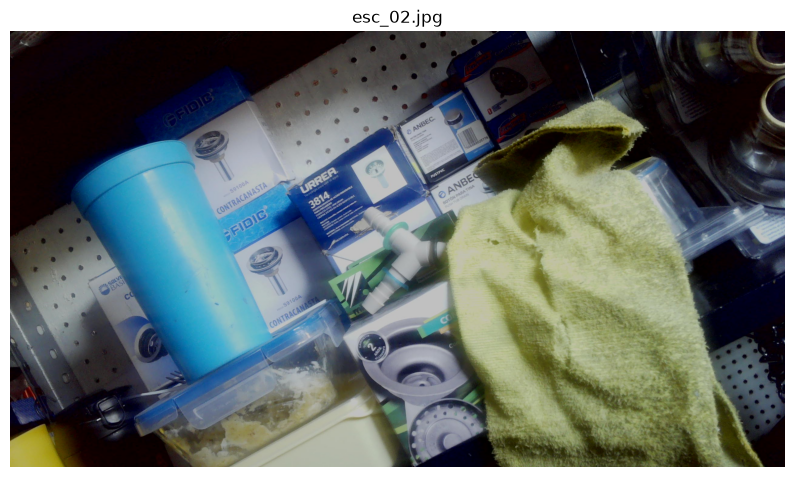

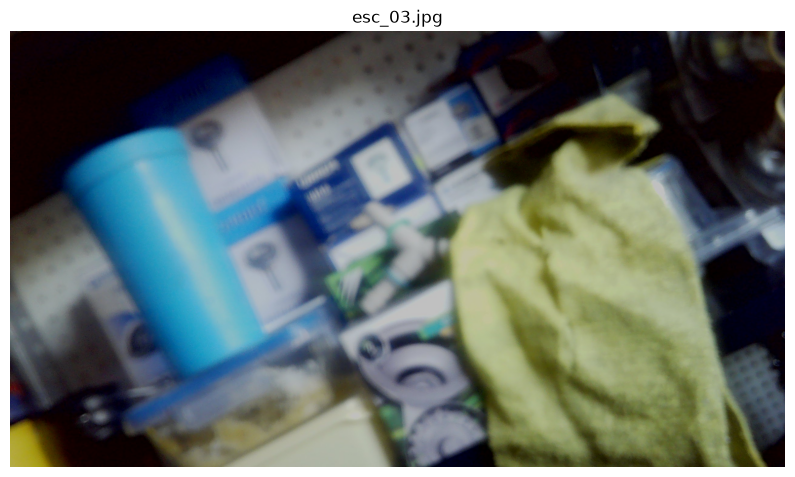

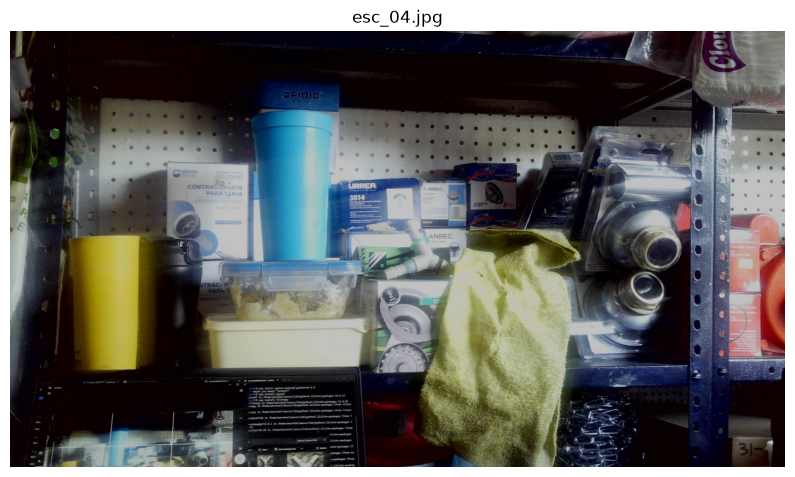

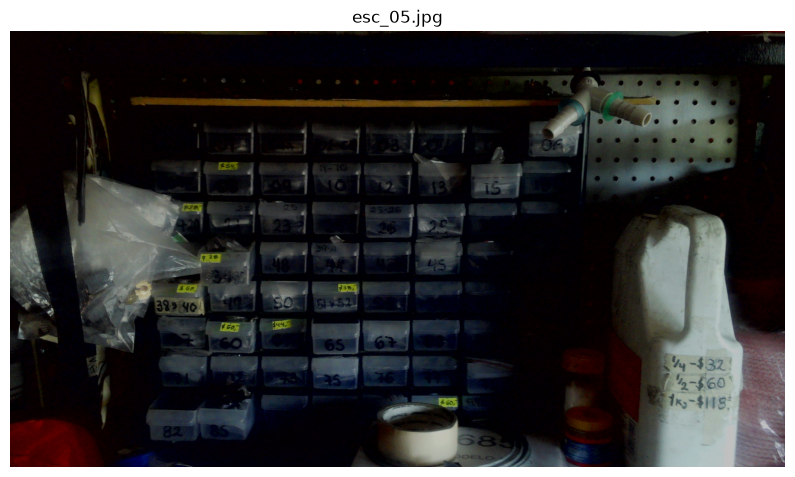

...

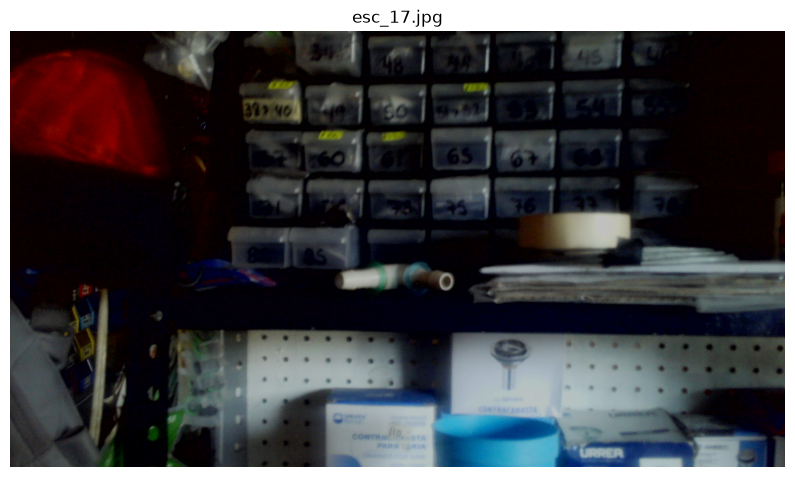

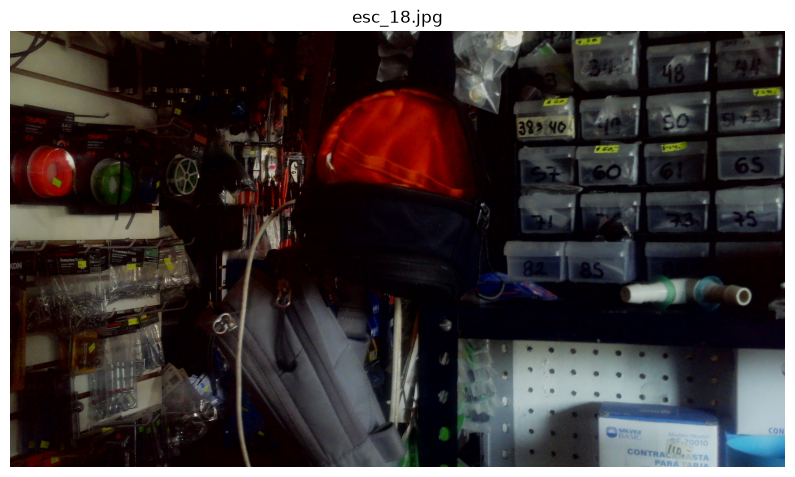

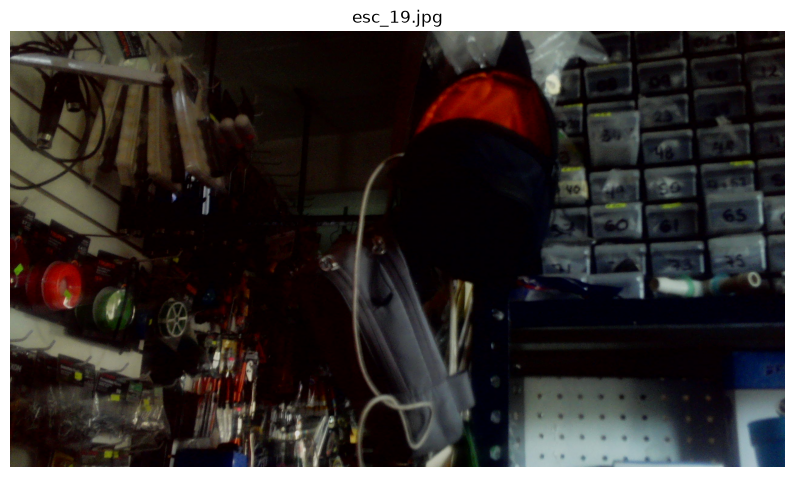

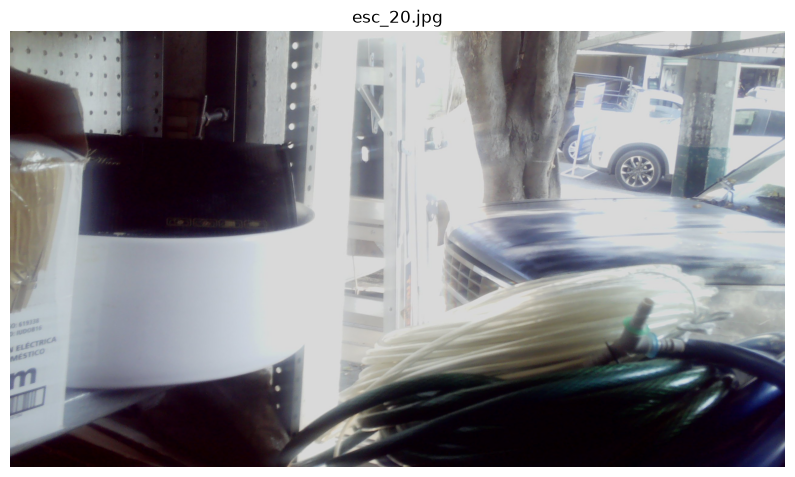

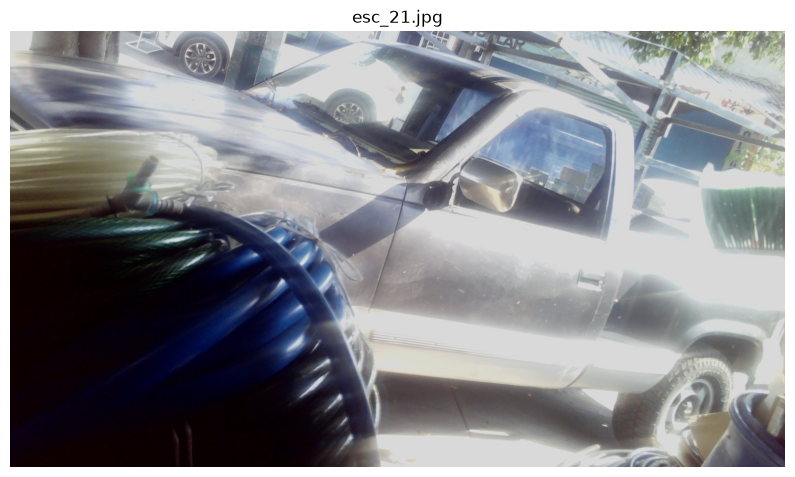

In [5]:
scene_paths = sorted(SCENES_DIR.glob("esc_*.jpg"))
print(f"Escenas encontradas: {len(scene_paths)}")
for p in scene_paths:
    img = cv2.imread(str(p))
    print(f"  {p.name}: {None if img is None else img.shape}")

# Mostrar las primeras 4 como muestra
for p in scene_paths[:]:
    img = cv2.imread(str(p))
    show(img, p.name)

In [6]:
scenes = {}
for p in scene_paths:
    img = cv2.imread(str(p))
    if img is not None:
        scenes[p.stem] = img

print(f"Escenas cargadas correctamente: {len(scenes)} / {len(scene_paths)}")
print("Nombres:", list(scenes.keys()))

Escenas cargadas correctamente: 21 / 21
Nombres: ['esc_01', 'esc_02', 'esc_03', 'esc_04', 'esc_05', 'esc_06', 'esc_07', 'esc_08', 'esc_09', 'esc_10', 'esc_11', 'esc_12', 'esc_13', 'esc_14', 'esc_15', 'esc_16', 'esc_17', 'esc_18', 'esc_19', 'esc_20', 'esc_21']


In [7]:
sift = cv2.SIFT_create()
kp_ref_sift, des_ref_sift = sift.detectAndCompute(ref, None)
print("SIFT ref — keypoints:", len(kp_ref_sift),
      "| descriptores:", None if des_ref_sift is None else des_ref_sift.shape)

orb = cv2.ORB_create(nfeatures=1000)
kp_ref_orb, des_ref_orb = orb.detectAndCompute(ref, None)
print("ORB ref  — keypoints:", len(kp_ref_orb),
      "| descriptores:", None if des_ref_orb is None else des_ref_orb.shape)

SIFT ref — keypoints: 263 | descriptores: (263, 128)
ORB ref  — keypoints: 298 | descriptores: (298, 32)


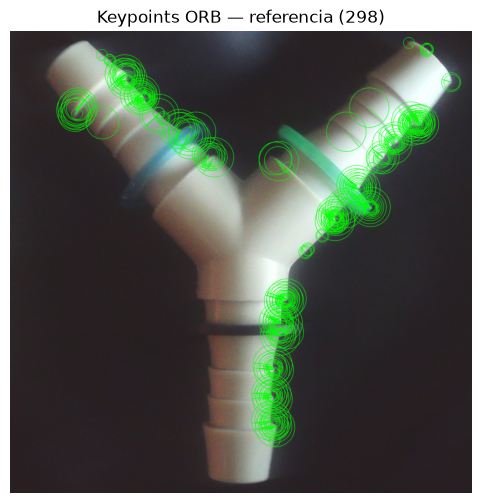

In [8]:
img_kp_ref = cv2.drawKeypoints(
    ref, kp_ref_orb, None,
    color=(0, 255, 0),
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
)
show(img_kp_ref, f"Keypoints ORB — referencia ({len(kp_ref_orb)})")

In [9]:
import time

def evaluate_pair(ref, scene, detector_name="ORB", ratio=0.75, ransac_thr=3.0):
    t0 = time.time()

    if detector_name == "SIFT":
        det = cv2.SIFT_create()
        norm = cv2.NORM_L2
    else:
        det = cv2.ORB_create(nfeatures=1000)
        norm = cv2.NORM_HAMMING

    kp1, d1 = det.detectAndCompute(ref, None)
    kp2, d2 = det.detectAndCompute(scene, None)

    result = {
        "detector": detector_name,
        "kp_ref": 0 if kp1 is None else len(kp1),
        "kp_scene": 0 if kp2 is None else len(kp2),
        "good_matches": 0,
        "inliers": 0,
        "H": None,
        "mask": None,
        "kp1": kp1,
        "kp2": kp2,
        "good": [],
        "projected": None,
        "error": None,
    }

    if d1 is None or d2 is None or len(kp1) < 4 or len(kp2) < 4:
        result["error"] = "pocos keypoints"
        result["time_s"] = time.time() - t0
        return result

    bf = cv2.BFMatcher(norm, crossCheck=False)
    try:
        knn = bf.knnMatch(d1, d2, k=2)
    except cv2.error as e:
        result["error"] = f"knnMatch: {e}"
        result["time_s"] = time.time() - t0
        return result

    good = [m for m, n in knn if m.distance < ratio * n.distance]
    result["good"] = good
    result["good_matches"] = len(good)

    if len(good) < 4:
        result["error"] = "menos de 4 matches buenos"
        result["time_s"] = time.time() - t0
        return result

    src_pts = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)

    try:
        H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, ransac_thr)
    except cv2.error as e:
        result["error"] = f"findHomography: {e}"
        result["time_s"] = time.time() - t0
        return result

    if H is None:
        result["error"] = "H nula"
        result["time_s"] = time.time() - t0
        return result

    result["H"] = H
    result["mask"] = mask
    result["inliers"] = int(mask.sum()) if mask is not None else 0

    h, w = ref.shape[:2]
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    try:
        result["projected"] = cv2.perspectiveTransform(corners, H)
    except cv2.error as e:
        result["error"] = f"perspectiveTransform: {e}"

    result["time_s"] = time.time() - t0
    return result

In [10]:
results_orb = {}
for name, scene in scenes.items():
    results_orb[name] = evaluate_pair(ref, scene, detector_name="ORB")

print(f"{'Escena':<10} {'kp_ref':>7} {'kp_esc':>7} {'matches':>8} {'inliers':>8} {'tiempo(s)':>10} {'error':<30}")
print("-" * 90)
for name, r in results_orb.items():
    err = r["error"] or ""
    print(f"{name:<10} {r['kp_ref']:>7} {r['kp_scene']:>7} {r['good_matches']:>8} {r['inliers']:>8} {r['time_s']:>10.3f} {err:<30}")

Escena      kp_ref  kp_esc  matches  inliers  tiempo(s) error                         
------------------------------------------------------------------------------------------
esc_01         298    1000        5        0      0.034 H nula                        
esc_02         298    1000        5        5      0.039                               
esc_03         298      75        8        5      0.029                               
esc_04         298    1000        0        0      0.040 menos de 4 matches buenos     
esc_05         298    1000        1        0      0.030 menos de 4 matches buenos     
esc_06         298    1000        2        0      0.033 menos de 4 matches buenos     
esc_07         298    1000        0        0      0.034 menos de 4 matches buenos     
esc_08         298    1000        1        0      0.032 menos de 4 matches buenos     
esc_09         298    1000        0        0      0.035 menos de 4 matches buenos     
esc_10         298    1000        2    

In [11]:
results_sift = {}
for name, scene in scenes.items():
    results_sift[name] = evaluate_pair(ref, scene, detector_name="SIFT")

print(f"{'Escena':<10} {'kp_ref':>7} {'kp_esc':>7} {'matches':>8} {'inliers':>8} {'tiempo(s)':>10} {'error':<30}")
print("-" * 90)
for name, r in results_sift.items():
    err = r["error"] or ""
    print(f"{name:<10} {r['kp_ref']:>7} {r['kp_scene']:>7} {r['good_matches']:>8} {r['inliers']:>8} {r['time_s']:>10.3f} {err:<30}")

Escena      kp_ref  kp_esc  matches  inliers  tiempo(s) error                         
------------------------------------------------------------------------------------------
esc_01         263    7382       20        4      0.260                               
esc_02         263    6127        7        4      0.380                               
esc_03         263     291       78        4      0.332                               
esc_04         263   13889        4        4      0.361                               
esc_05         263    3753        7        4      0.368                               
esc_06         263    4903        9        4      0.320                               
esc_07         263    3400        7        4      0.378                               
esc_08         263    3008        3        0      0.337 menos de 4 matches buenos     
esc_09         263    4256       14        4      0.377                               
esc_10         263    4899       13    

In [12]:
def rank_results(results):
    items = [(n, r) for n, r in results.items() if r["error"] is None]
    items.sort(key=lambda x: (x[1]["inliers"], x[1]["good_matches"]), reverse=True)
    return items

rank_orb = rank_results(results_orb)
rank_sift = rank_results(results_sift)

print("=== Ranking ORB (mejores primero) ===")
for n, r in rank_orb:
    print(f"  {n}: inliers={r['inliers']:>4}  matches={r['good_matches']:>4}  t={r['time_s']:.3f}s")

print("\n=== Ranking SIFT (mejores primero) ===")
for n, r in rank_sift:
    print(f"  {n}: inliers={r['inliers']:>4}  matches={r['good_matches']:>4}  t={r['time_s']:.3f}s")

best_orb = rank_orb[0][0] if rank_orb else None
best_sift = rank_sift[0][0] if rank_sift else None
print(f"\nMejor escena para ORB : {best_orb}")
print(f"Mejor escena para SIFT: {best_sift}")

=== Ranking ORB (mejores primero) ===
  esc_03: inliers=   5  matches=   8  t=0.029s
  esc_02: inliers=   5  matches=   5  t=0.039s
  esc_16: inliers=   4  matches=   4  t=0.035s

=== Ranking SIFT (mejores primero) ===
  esc_17: inliers=   5  matches=  14  t=0.310s
  esc_10: inliers=   5  matches=  13  t=0.378s
  esc_21: inliers=   5  matches=  12  t=0.366s
  esc_03: inliers=   4  matches=  78  t=0.332s
  esc_01: inliers=   4  matches=  20  t=0.260s
  esc_19: inliers=   4  matches=  19  t=0.398s
  esc_16: inliers=   4  matches=  15  t=0.360s
  esc_09: inliers=   4  matches=  14  t=0.377s
  esc_13: inliers=   4  matches=  14  t=0.350s
  esc_14: inliers=   4  matches=  11  t=0.316s
  esc_15: inliers=   4  matches=  11  t=0.346s
  esc_12: inliers=   4  matches=  10  t=0.362s
  esc_06: inliers=   4  matches=   9  t=0.320s
  esc_18: inliers=   4  matches=   9  t=0.336s
  esc_02: inliers=   4  matches=   7  t=0.380s
  esc_05: inliers=   4  matches=   7  t=0.368s
  esc_07: inliers=   4  match

In [13]:
def draw_detection(ref, scene, result, title=""):
    if result["H"] is None or result["projected"] is None:
        show(scene, f"{title} — sin detección")
        return
    scene_draw = scene.copy()
    cv2.polylines(scene_draw, [np.int32(result["projected"])], True, (0, 255, 0), 3)
    show(scene_draw, f"{title} — inliers={result['inliers']}")

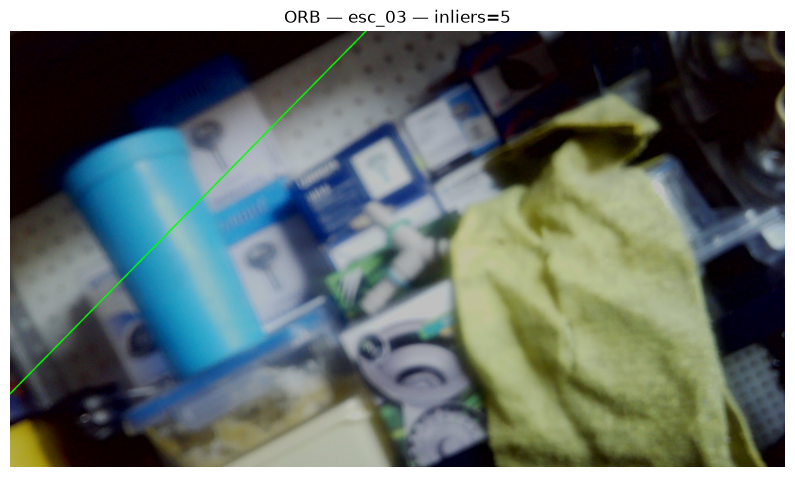

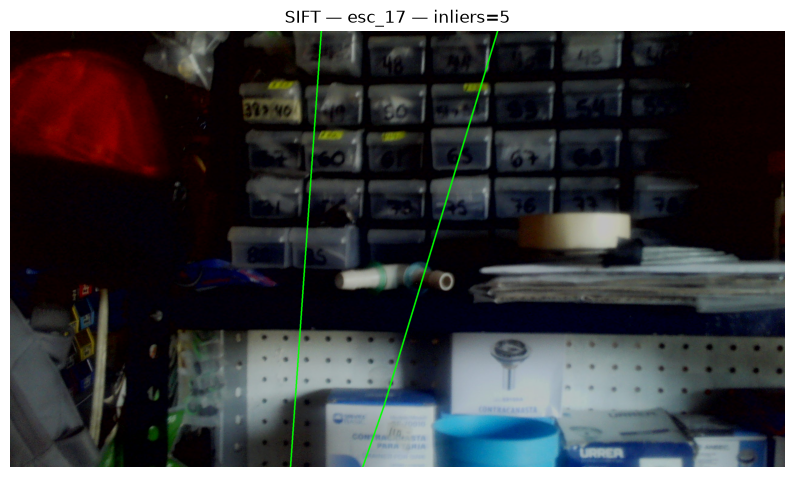

In [14]:
if best_orb:
    draw_detection(ref, scenes[best_orb], results_orb[best_orb], f"ORB — {best_orb}")
if best_sift:
    draw_detection(ref, scenes[best_sift], results_sift[best_sift], f"SIFT — {best_sift}")

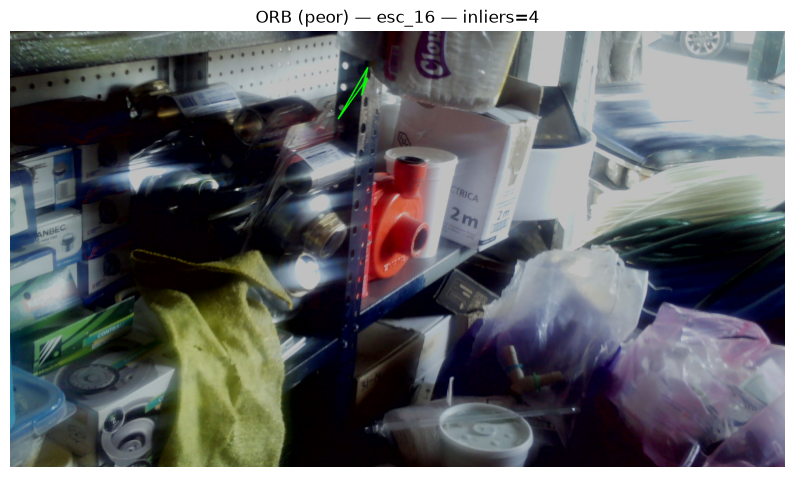

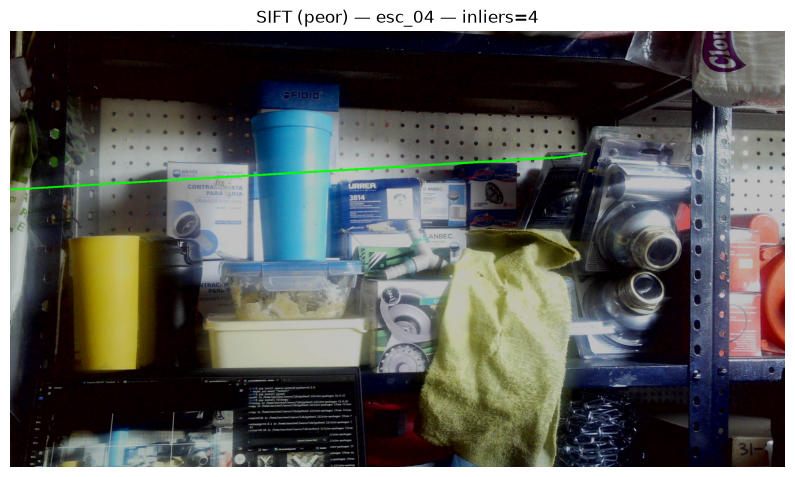

In [15]:
if rank_orb:
    worst_orb = rank_orb[-1][0]
    draw_detection(ref, scenes[worst_orb], results_orb[worst_orb], f"ORB (peor) — {worst_orb}")
if rank_sift:
    worst_sift = rank_sift[-1][0]
    draw_detection(ref, scenes[worst_sift], results_sift[worst_sift], f"SIFT (peor) — {worst_sift}")

In [16]:
def summarize(results):
    valid = [r for r in results.values() if r["error"] is None]
    if not valid:
        return {"n_ok": 0, "inliers_med": 0, "matches_med": 0, "tiempo_med": 0}
    return {
        "n_ok": len(valid),
        "inliers_med": float(np.median([r["inliers"] for r in valid])),
        "matches_med": float(np.median([r["good_matches"] for r in valid])),
        "tiempo_med": float(np.median([r["time_s"] for r in valid])),
    }

s_orb = summarize(results_orb)
s_sift = summarize(results_sift)

print("Métrica              ORB        SIFT")
print("-" * 40)
print(f"Escenas con éxito    {s_orb['n_ok']:>4}       {s_sift['n_ok']:>4}")
print(f"Inliers (mediana)    {s_orb['inliers_med']:>8.1f}   {s_sift['inliers_med']:>8.1f}")
print(f"Matches (mediana)    {s_orb['matches_med']:>8.1f}   {s_sift['matches_med']:>8.1f}")
print(f"Tiempo (mediana, s)  {s_orb['tiempo_med']:>8.3f}   {s_sift['tiempo_med']:>8.3f}")

Métrica              ORB        SIFT
----------------------------------------
Escenas con éxito       3         19
Inliers (mediana)         5.0        4.0
Matches (mediana)         5.0       11.0
Tiempo (mediana, s)     0.035      0.360


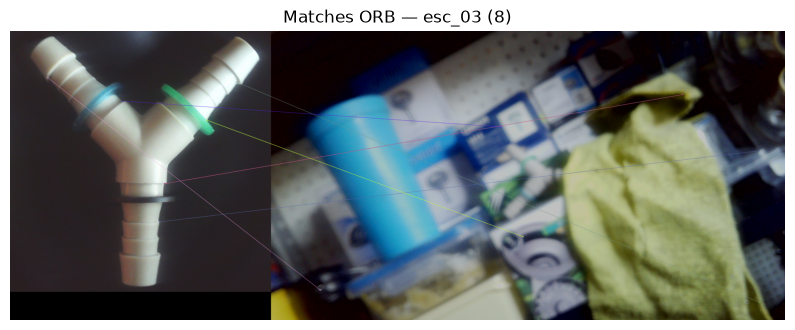

In [17]:
if best_orb:
    scene = scenes[best_orb]
    r = results_orb[best_orb]
    img_matches = cv2.drawMatches(
        ref, r["kp1"], scene, r["kp2"], r["good"], None, flags=2
    )
    show(img_matches, f"Matches ORB — {best_orb} ({r['good_matches']})")

Mejor escena ORB: esc_03
H =
 [[ 2.67454233e+00 -4.69993374e-02 -2.64888380e+02]
 [-2.01387015e+00  4.64140274e-01  1.46688836e+03]
 [ 5.95487972e-04 -7.91126063e-04  1.00000000e+00]]
Inliers: 5 / 8


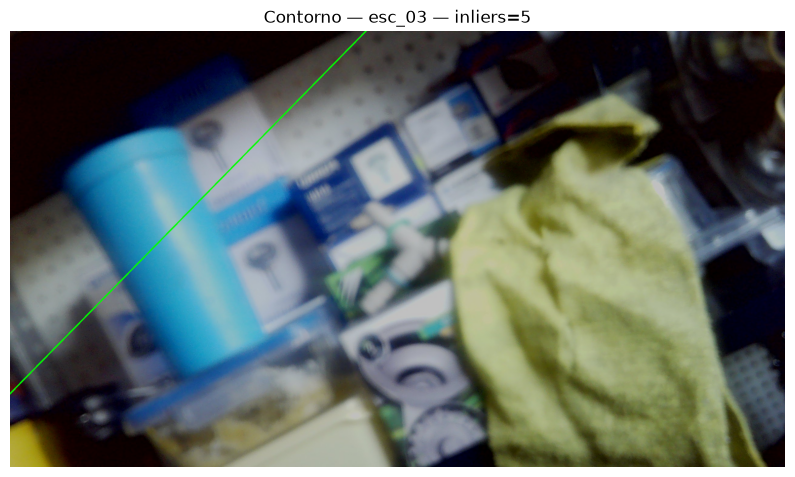

In [18]:
if best_orb:
    r = results_orb[best_orb]
    print("Mejor escena ORB:", best_orb)
    print("H =\n", r["H"])
    print("Inliers:", r["inliers"], "/", r["good_matches"])
    draw_detection(ref, scenes[best_orb], r, f"Contorno — {best_orb}")

In [19]:
if best_orb:
    r = results_orb[best_orb]
    scene = scenes[best_orb]
    H = r["H"]
    h, w = ref.shape[:2]

    obj_pts = np.float32([[0, 0, 0], [w, 0, 0], [w, h, 0], [0, h, 0]])
    img_pts = r["projected"].reshape(-1, 2).astype(np.float32)

    fx = fy = max(scene.shape[:2])
    cx, cy = scene.shape[1] / 2, scene.shape[0] / 2
    K = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]], dtype=np.float64)

    ok, rvec, tvec = cv2.solvePnP(obj_pts, img_pts, K, None)
    print("solvePnP ok:", ok)
    print("rvec:", rvec.ravel())
    print("tvec:", tvec.ravel())

solvePnP ok: True
rvec: [26.05085741 -3.8613703  32.79687598]
tvec: [  1889.4774729  -25164.78621553   2851.3013051 ]


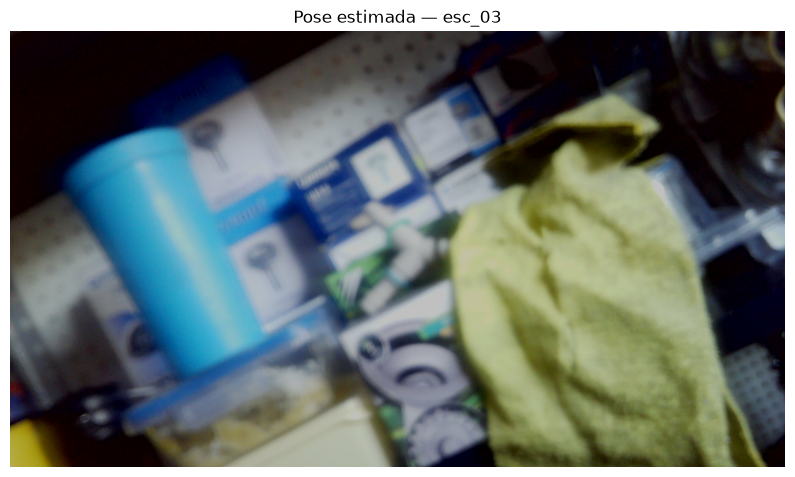

In [20]:
if best_orb and ok:
    axis_len = 1.0
    axis_3d = np.float32([[0, 0, 0], [axis_len, 0, 0], [0, axis_len, 0], [0, 0, -axis_len]])
    imgpts, _ = cv2.projectPoints(axis_3d, rvec, tvec, K, None)
    imgpts = np.int32(imgpts).reshape(-1, 2)
    origin = tuple(imgpts[0])

    scene_axes = scene.copy()
    cv2.line(scene_axes, origin, tuple(imgpts[1]), (0, 0, 255), 3)   # X rojo
    cv2.line(scene_axes, origin, tuple(imgpts[2]), (0, 255, 0), 3)   # Y verde
    cv2.line(scene_axes, origin, tuple(imgpts[3]), (255, 0, 0), 3)   # Z azul
    show(scene_axes, f"Pose estimada — {best_orb}")

In [21]:
kf = cv2.KalmanFilter(6, 3)
kf.transitionMatrix = np.eye(6, dtype=np.float32)
kf.transitionMatrix[0, 3] = 1
kf.transitionMatrix[1, 4] = 1
kf.transitionMatrix[2, 5] = 1

kf.measurementMatrix = np.zeros((3, 6), dtype=np.float32)
kf.measurementMatrix[0, 0] = 1
kf.measurementMatrix[1, 1] = 1
kf.measurementMatrix[2, 2] = 1

kf.processNoiseCov = np.eye(6, dtype=np.float32) * 0.03
kf.measurementNoiseCov = np.eye(3, dtype=np.float32) * 0.1
kf.errorCovPost = np.eye(6, dtype=np.float32)

np.random.seed(0)
true = np.array([1.0, 2.0, 5.0], dtype=np.float32)
measurements = [true + np.random.normal(0, 0.2, 3).astype(np.float32) for _ in range(20)]

corrected = []
for z in measurements:
    kf.predict()
    c = kf.correct(z.reshape(3, 1))
    corrected.append(c[:3].ravel())

corrected = np.array(corrected)
print("Mediciones ruidosas (primeras 3):\n", np.array(measurements[:3]))
print("Pose suavizada (primeras 3):\n", corrected[:3])

Mediciones ruidosas (primeras 3):
 [[1.3528105 2.0800314 5.1957474]
 [1.4481786 2.3735116 4.8045444]
 [1.1900177 1.9697286 4.9793563]]
Pose suavizada (primeras 3):
 [[1.2892983 1.9823774 4.9518156]
 [1.5023144 2.4400563 5.0985694]
 [1.3072174 2.1672769 5.12571  ]]


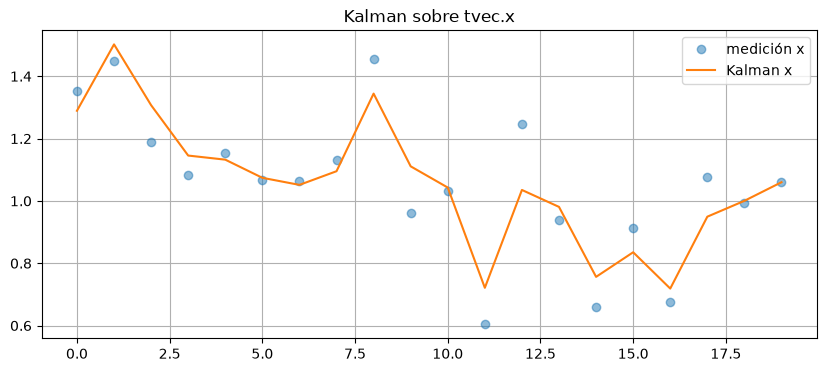

In [22]:
plt.figure(figsize=(10, 4))
plt.plot([m[0] for m in measurements], "o", label="medición x", alpha=0.5)
plt.plot(corrected[:, 0], "-", label="Kalman x")
plt.legend()
plt.title("Kalman sobre tvec.x")
plt.grid(True)
plt.show()

## 9. Etapa 6 — Pipeline de video (pendiente)

Cuando `src/pipeline/video_pipeline.py` esté implementado, se usará así:

```python
from src.pipeline.video_pipeline import VideoPipeline
pipe = VideoPipeline(reference_path="../data/reference/libro.jpg",
                     config_path="../configs/default.yaml")
pipe.run(video_path="...", output_path="...")